###Câu a) Đọc bộ dữ liệu MNIST

In [ ]:
def in_thong_tin():
    print("Họ và tên: Nguyễn Gia Huy")
    print("Mã sinh viên: 6451071027")
    print("-" * 30)

in_thong_tin()

from tensorflow.keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("Đã đọc xong dữ liệu MNIST")

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Đã đọc xong dữ liệu MNIST


###Câu b) In kích thước tập train, test

In [ ]:
in_thong_tin()

print("train_images:", train_images.shape)   # (60000, 28, 28)
print("train_labels:", train_labels.shape)   # (60000,)
print("test_images :", test_images.shape)    # (10000, 28, 28)
print("test_labels :", test_labels.shape)    # (10000,)

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
train_images: (60000, 28, 28)
train_labels: (60000,)
test_images : (10000, 28, 28)
test_labels : (10000,)


###Câu c) Chuẩn hóa pixel về [0,1]

In [ ]:
in_thong_tin()

train_images = train_images / 255.0
test_images = test_images / 255.0

print("Min/Max train:", train_images.min(), train_images.max())
print("Min/Max test :", test_images.min(), test_images.max())

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Min/Max train: 0.0 1.0
Min/Max test : 0.0 1.0


###Câu d) Chia train thành train và validation theo tỷ lệ 8:2

In [ ]:
in_thong_tin()
from sklearn.model_selection import train_test_split

train_images, validation_images, train_labels, validation_labels = train_test_split(
    train_images, train_labels, test_size=0.2, random_state=42)

print("train_images     :", train_images.shape)        # (48000, 28, 28)
print("train_labels     :", train_labels.shape)
print("validation_images:", validation_images.shape)   # (12000, 28, 28)
print("validation_labels:", validation_labels.shape)

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
train_images     : (48000, 28, 28)
train_labels     : (48000,)
validation_images: (12000, 28, 28)
validation_labels: (12000,)


###Câu e) Xây dựng Neural Network

In [ ]:
in_thong_tin()
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout, Input

so_lop = 10

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),                              # 28x28 -> 784
    Dense(128, activation='relu'),
    Dropout(0.2),                           # tắt ngẫu nhiên 20% neuron
    Dense(so_lop, activation='softmax')
])
model.summary()

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

###Câu f) Biên dịch mô hình

In [ ]:
in_thong_tin()

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


###Câu g) Huấn luyện mô hình

In [ ]:
in_thong_tin()

history = model.fit(train_images, train_labels,
                    validation_data=(validation_images, validation_labels),
                    epochs=5, batch_size=32)

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9079 - loss: 0.3172 - val_accuracy: 0.9503 - val_loss: 0.1708
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9526 - loss: 0.1587 - val_accuracy: 0.9642 - val_loss: 0.1204
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9645 - loss: 0.1193 - val_accuracy: 0.9706 - val_loss: 0.1035
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9710 - loss: 0.0957 - val_accuracy: 0.9743 - val_loss: 0.0919
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9743 - loss: 0.0820 - val_accuracy: 0.9745 - val_loss: 0.0884


###Câu h) Vẽ biểu đồ accuracy, loss sau mỗi epoch

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


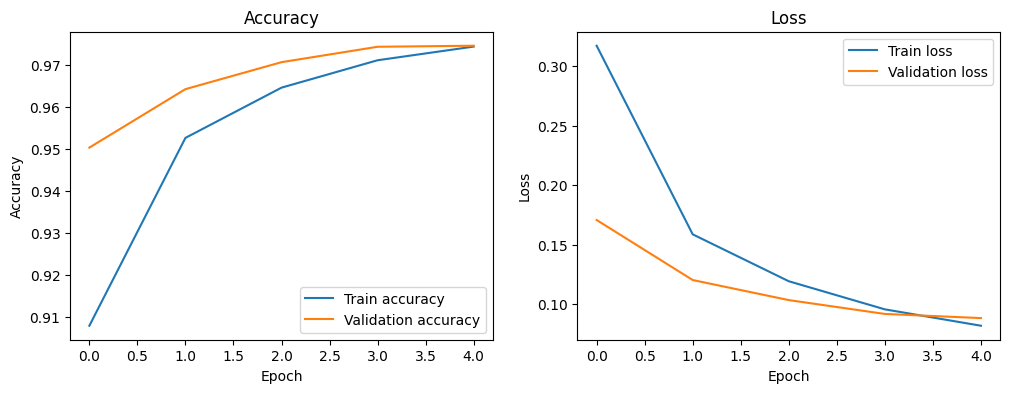

In [ ]:
in_thong_tin()
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history['accuracy'], label='Train accuracy')
ax[0].plot(history.history['val_accuracy'], label='Validation accuracy')
ax[0].set_title('Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy')
ax[0].legend()

ax[1].plot(history.history['loss'], label='Train loss')
ax[1].plot(history.history['val_loss'], label='Validation loss')
ax[1].set_title('Loss'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Loss')
ax[1].legend()

plt.show()

###Câu i) Dự đoán phân lớp cho tập test

In [ ]:
in_thong_tin()
import numpy as np

y_prob = model.predict(test_images)
y_pred = np.argmax(y_prob, axis=1)

print("Xác suất shape:", y_prob.shape)     # (10000, 10)
print("10 nhãn dự đoán đầu:", y_pred[:10])
print("10 nhãn thực tế đầu:", test_labels[:10])

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Xác suất shape: (10000, 10)
10 nhãn dự đoán đầu: [7 2 1 0 4 1 4 9 5 9]
10 nhãn thực tế đầu: [7 2 1 0 4 1 4 9 5 9]


###Câu j) Accuracy trên tập test

In [ ]:
in_thong_tin()
from sklearn.metrics import accuracy_score

print("Accuracy trên tập test:", accuracy_score(test_labels, y_pred))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Accuracy trên tập test: 0.9759


###Câu k) Precision, Recall, F1-score

In [ ]:
in_thong_tin()
from sklearn.metrics import classification_report

print(classification_report(test_labels, y_pred, digits=4))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
              precision    recall  f1-score   support

           0     0.9690    0.9898    0.9793       980
           1     0.9877    0.9877    0.9877      1135
           2     0.9739    0.9758    0.9748      1032
           3     0.9733    0.9762    0.9748      1010
           4     0.9707    0.9796    0.9752       982
           5     0.9840    0.9664    0.9751       892
           6     0.9781    0.9781    0.9781       958
           7     0.9774    0.9689    0.9731      1028
           8     0.9682    0.9702    0.9692       974
           9     0.9759    0.9643    0.9701      1009

    accuracy                         0.9759     10000
   macro avg     0.9758    0.9757    0.9757     10000
weighted avg     0.9759    0.9759    0.9759     10000



###Câu l) Confusion matrix bằng heatmap

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


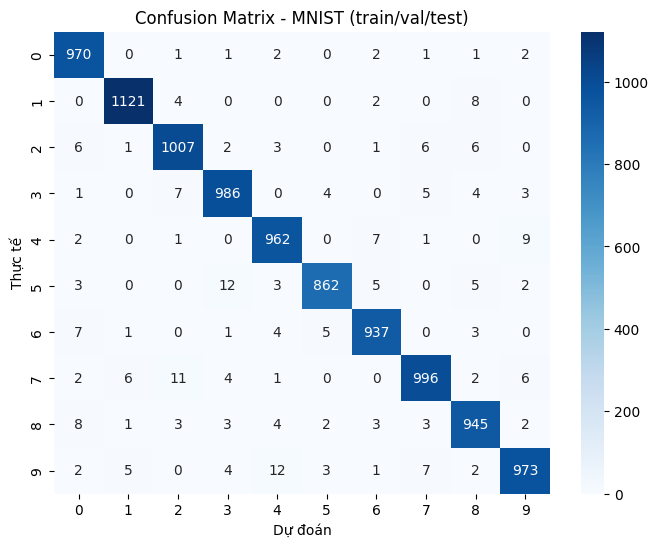

In [ ]:
in_thong_tin()
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(test_labels, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Dự đoán'); plt.ylabel('Thực tế')
plt.title('Confusion Matrix - MNIST (train/val/test)')
plt.show()

###Câu m) Kết quả phân lớp của 5 ảnh đầu tiên trong tập test

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


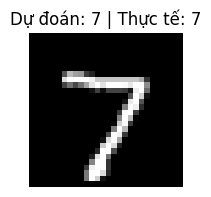

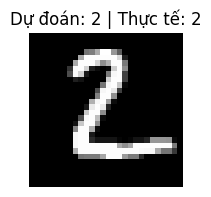

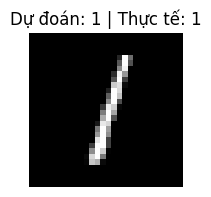

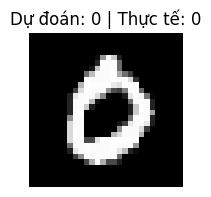

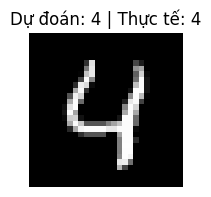

In [ ]:
in_thong_tin()

for image_index in range(5):
    img = np.expand_dims(test_images[image_index], axis=0)   # (1, 28, 28)
    pred = np.argmax(model.predict(img, verbose=0), axis=1)[0]

    plt.figure(figsize=(2, 2))
    plt.imshow(test_images[image_index], cmap='gray')
    plt.title(f"Dự đoán: {pred} | Thực tế: {test_labels[image_index]}")
    plt.axis('off')
    plt.show()

###Câu n) 5 kết quả đầu tiên phân lớp sai

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Tổng số ảnh dự đoán sai: 241


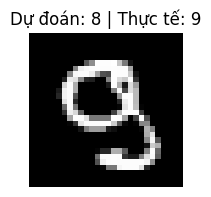

Ảnh index 151: dự đoán = 8, thực tế = 9


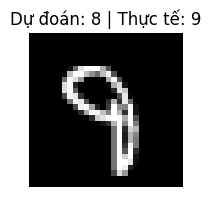

Ảnh index 193: dự đoán = 8, thực tế = 9


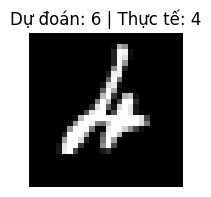

Ảnh index 247: dự đoán = 6, thực tế = 4


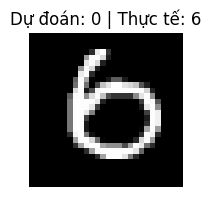

Ảnh index 259: dự đoán = 0, thực tế = 6


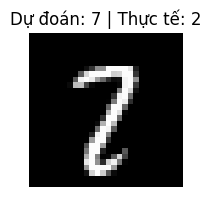

Ảnh index 321: dự đoán = 7, thực tế = 2


In [ ]:
in_thong_tin()

sai_idx = np.where(y_pred != test_labels)[0]
print("Tổng số ảnh dự đoán sai:", len(sai_idx))

for i in sai_idx[:5]:
    plt.figure(figsize=(2, 2))
    plt.imshow(test_images[i], cmap='gray')
    plt.title(f"Dự đoán: {y_pred[i]} | Thực tế: {test_labels[i]}")
    plt.axis('off')
    plt.show()
    print(f"Ảnh index {i}: dự đoán = {y_pred[i]}, thực tế = {test_labels[i]}")